# ESS 배터리 수명 예측 — 03. 모델 개발 및 평가

Day 1 모델 설계 전략의 후보 모델을 `src/train.py` 파이프라인으로 학습·평가하고, 단계별 성능과 Gap 을 정리한 뒤 **원논문 성능과 비교**하고 오류를 분석합니다.

- **Target** : `log10(cycle_life)` · **Metric** : 사이클 단위 MAPE (%) · **원논문 목표** : 9.1%
- **분할** : Train = Batch 1 중 32셀(정책 단위 5-fold CV) · Valid = Batch 1 Hold-out 9셀(정책 단위) · Test = Batch 2 39셀 (+ Batch 3 40셀 추가 검증)
- **Gap** = 뒤 단계 MAPE − 앞 단계 MAPE, (+) 는 성능 저하

## 0. Setup — 파이프라인 실행

In [1]:
import sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.features import FEATURE_SETS, TARGET
from src.train import run, PAPER_TARGET_MAPE

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
plt.rcParams.update({'figure.figsize': (13, 4.5), 'font.size': 11, 'axes.grid': True, 'grid.alpha': .3,
                     'axes.spines.top': False, 'axes.spines.right': False})
GROUP_COLOR = {'B1': '#3B6EA8', 'B2-standard': '#D1495B', 'B2-newstructure': '#F4A259', 'B3': '#2E9E6B'}
GROUPS = list(GROUP_COLOR)
FIG = ROOT / 'results' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

In [2]:
# python -m src.train 과 같은 파이프라인 : results/ 에 성능표·예측·계수 저장
perf, data = run(out_dir=ROOT / 'results', processed_dir=ROOT / 'data' / 'processed', verbose=False)
pred = pd.read_csv(ROOT / 'results' / 'predictions.csv')
coef = pd.read_csv(ROOT / 'results' / 'coefficients.csv', index_col=0)
SEL = perf.loc[perf.selected, 'model'].item()
pred['signed_pe'] = (pred.pred_life - pred.cycle_life) / pred.cycle_life * 100   # (+) 과대예측
print('선택 모델 :', SEL)

선택 모델 : ElasticNet / F3


## 1. 후보 모델 비교

**ISSUE** : Day 1 후보 모델 중 무엇이 가장 좋은가? 선택은 테스트를 보지 않고 Batch 1 만으로 이루어지는가?

- **선택 기준** : Batch 1 의 모든 셀(41)에 대한 out-of-fold MAPE (train CV 32셀 + valid 9셀). 테스트(Batch 2·3)는 선택에 쓰지 않습니다.

,role,params,Train CV,Valid,B1 OOF (선택 기준),Test B2,B2 standard,B2 newstructure,Test B3
model,,,,,,,,,
LinearRegression / F1,베이스라인 (원논문 Variance model),{},9.7,8.7,9.7,27.2,28.5,22.7,12.8
ElasticNet / F2,1순위 : 외삽 가능 + 정규화,"{""alpha"": 0.01, ""l1_ratio"": 0.9}",9.5,8.2,9.3,29.2,31.8,20.8,12.5
Huber / F2,긴 꼬리에 강건한 선형,"{""alpha"": 0.0001, ""epsilon"": 1.35}",9.7,10.0,10.1,28.4,30.0,22.8,12.6
RandomForest / F2,"비교군 : 비선형, 외삽 불가","{""max_depth"": 5, ""min_samples_leaf"": 1}",13.6,8.0,13.4,36.3,38.0,30.8,14.0
XGBoost / F2,"비교군 : 비선형, 외삽 불가","{""max_depth"": 2, ""min_child_weight"": 1}",14.3,12.0,14.1,37.5,35.6,44.0,27.5
ElasticNet / F1,피처셋 비교 : F1,"{""alpha"": 0.01, ""l1_ratio"": 0.9}",9.5,8.2,9.3,29.2,31.8,20.8,12.5
ElasticNet / F3,피처셋 비교 : 배치 과적합 확인,"{""alpha"": 0.001, ""l1_ratio"": 0.9}",8.5,8.9,9.0,15.7,15.4,16.7,14.8
ElasticNet / F3+Policy,피처셋 비교 : 정책 피처 과적합 확인,"{""alpha"": 0.001, ""l1_ratio"": 0.9}",10.0,7.7,10.0,25.0,28.8,12.4,12.5


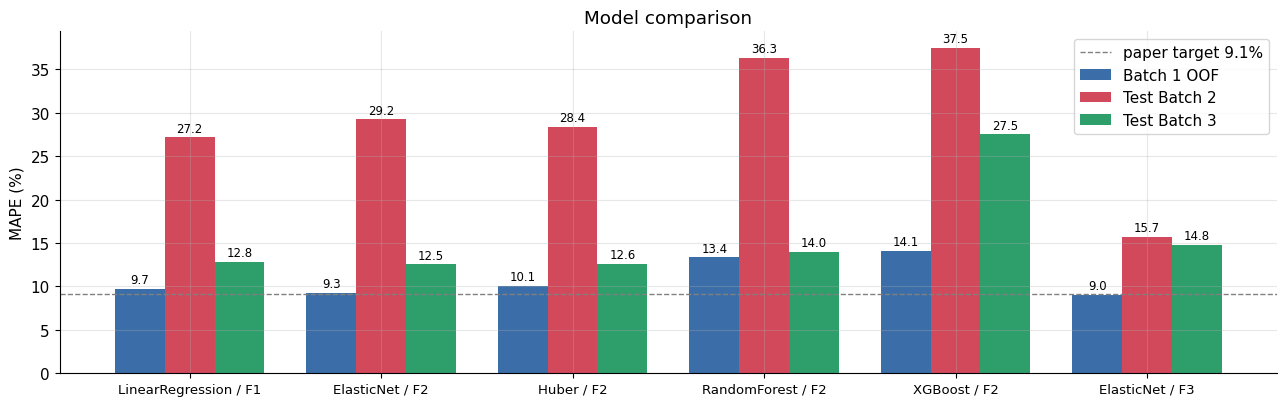

In [3]:
cols = ['model', 'role', 'params', 'train_cv_mape', 'valid_mape', 'b1_oof_mape',
        'test_b2_mape', 'test_b2_standard_mape', 'test_b2_newstructure_mape', 'test_b3_mape']
table = perf[cols].rename(columns={'train_cv_mape': 'Train CV', 'valid_mape': 'Valid', 'b1_oof_mape': 'B1 OOF (선택 기준)',
                                   'test_b2_mape': 'Test B2', 'test_b2_standard_mape': 'B2 standard',
                                   'test_b2_newstructure_mape': 'B2 newstructure', 'test_b3_mape': 'Test B3'})
display(table.set_index('model').style.format(precision=1)
        .highlight_min(subset=['B1 OOF (선택 기준)'], color='#DCE6F2')
        .set_caption('후보 모델 성능 (MAPE %) — 음영 = 선택 기준 최저'))

main = perf[perf.feature_set.eq('F2') | perf.model.eq('LinearRegression / F1') | perf.model.eq(SEL)]
x = np.arange(len(main)); w = .26
fig, ax = plt.subplots(figsize=(13, 4.2))
for k, (col, lab, c) in enumerate([('b1_oof_mape', 'Batch 1 OOF', '#3B6EA8'), ('test_b2_mape', 'Test Batch 2', '#D1495B'),
                                   ('test_b3_mape', 'Test Batch 3', '#2E9E6B')]):
    b = ax.bar(x + (k - 1) * w, main[col], w, color=c, label=lab)
    ax.bar_label(b, fmt='%.1f', fontsize=8.5, padding=2)
ax.axhline(PAPER_TARGET_MAPE, ls='--', c='gray', lw=1, label='paper target 9.1%')
ax.set_xticks(x, main.model, fontsize=9.5); ax.set_ylabel('MAPE (%)'); ax.set_title('Model comparison'); ax.legend()
plt.tight_layout(); fig.savefig(FIG / 'model_comparison.png', dpi=150, bbox_inches='tight'); plt.show()

**[해석]**
- **Batch 1 안에서는 선형 모델이 원논문 수준입니다** (B1 OOF 9.0~10.1%). 트리 모델(RandomForest 13.4%, XGBoost 14.1%)은 41셀 소표본에서 이미 열세입니다.
- **선택 모델은 ElasticNet / F3** (B1 OOF 9.0%) 입니다.
- **Test Batch 2 에서는 모든 모델이 크게 나빠집니다.** 선형 F1·F2 계열은 27~29%, 트리 계열은 36~38%, F3 만 15.7% 입니다.
- ElasticNet / F2 의 결과가 F1 과 같은 이유는 정규화가 skew·kurt 계수를 0 으로 줄였기 때문입니다(4.2절) → **ΔQ 정보는 logvar 하나로 충분**합니다(원논문 Variance model 과 같은 결론).
- 참고 : 선택 기준을 Valid 단독(9셀)으로 하면 ElasticNet / F3+Policy(Valid 7.7%) 가 선택되지만, 이 모델은 Train CV 가 10.0% 로 Valid 와 어긋납니다. 9셀·5정책의 valid 는 표본이 작아, Batch 1 의 41셀 전체를 쓰는 OOF 기준을 사용했습니다. 모든 후보의 결과를 위 표에 함께 공개합니다.

## 2. 성능 리포팅

**ISSUE** : 선택 모델의 단계별 성능과 Gap 은 어떠한가?

In [4]:
s = perf.loc[perf.selected].iloc[0]
report = pd.DataFrame({
    'MAPE (%)': [s.train_cv_mape, s.valid_mape, s.test_b2_mape, s.gap_train_valid, s.gap_valid_test, s.gap_target_test],
    '비고': [f'정책 단위 5-fold 평균 (fold 표준편차 {s.train_cv_std:.1f})', '정책 단위 Hold-out 9셀',
           f'standard {s.test_b2_standard_mape:.1f} / newstructure {s.test_b2_newstructure_mape:.1f}',
           '(+) : 과적합 의심', '(+) : 배치간 일반화 저하 의심', f'Target : 원논문 {PAPER_TARGET_MAPE}%'],
}, index=['Train (Batch 1 CV)', 'Valid (Batch 1 Hold-out)', 'Test (Batch 2)',
          'Gap (Train-Valid)', 'Gap (Valid-Test)', 'Gap (Target-Test)'])
display(report.style.format({'MAPE (%)': '{:+.1f}'}, subset=pd.IndexSlice[report.index[3:], 'MAPE (%)'])
        .format({'MAPE (%)': '{:.1f}'}, subset=pd.IndexSlice[report.index[:3], 'MAPE (%)'])
        .set_caption(f'Reporting format (Regression) — {SEL}'))

report_b3 = pd.DataFrame({
    'MAPE (%)': [s.test_b3_mape, s.gap_b2_b3, s.gap_target_test_b3],
    '비고': ['원논문 secondary test 와 같은 파일 (2018-04-12)', 'Test 성능 간 비교 (B3 − B2)', 'Batch 3 기준, 원논문 성능 비교'],
}, index=['Test (Batch 3)', 'Gap (Batch2-Batch3)', 'Gap (Target-Test)'])
display(report_b3.style.format({'MAPE (%)': '{:.1f}'}, subset=pd.IndexSlice[['Test (Batch 3)'], 'MAPE (%)'])
        .format({'MAPE (%)': '{:+.1f}'}, subset=pd.IndexSlice[report_b3.index[1:], 'MAPE (%)'])
        .set_caption('Reporting format (Batch 3 — additional)'))

,MAPE (%),비고
Train (Batch 1 CV),8.5,정책 단위 5-fold 평균 (fold 표준편차 2.4)
Valid (Batch 1 Hold-out),8.9,정책 단위 Hold-out 9셀
Test (Batch 2),15.7,standard 15.4 / newstructure 16.7
Gap (Train-Valid),+0.4,(+) : 과적합 의심
Gap (Valid-Test),+6.8,(+) : 배치간 일반화 저하 의심
Gap (Target-Test),+6.6,Target : 원논문 9.1%


,MAPE (%),비고
Test (Batch 3),14.8,원논문 secondary test 와 같은 파일 (2018-04-12)
Gap (Batch2-Batch3),-0.9,Test 성능 간 비교 (B3 − B2)
Gap (Target-Test),+5.7,"Batch 3 기준, 원논문 성능 비교"


**[해석]**
- **Gap (Train−Valid) = +0.4%p** : Batch 1 안에서는 과적합이 거의 없습니다. 정책 단위로 분리한 valid 에서도 CV 와 비슷한 성능이 나옵니다.
- **Gap (Valid−Test) = +6.8%p** : 성능 저하의 대부분은 **배치가 바뀌는 데서** 생깁니다. 02 에서 확인했듯 B2-standard 는 수명 100% 가 학습 범위 밖인 외삽 문제입니다.
- **Gap (Target−Test) = +6.6%p** : 원논문 목표(9.1%)보다 6.6%p 높습니다. 원인은 3절에서 분석합니다.
- **Batch 3** : 14.8% 로 Batch 2 와 비슷한 수준입니다(Gap = B3 − B2 = −0.9%p). 수명 분포는 학습 범위 안이지만, 시험 조건(휴지 시간·CV 컷오프·IR 펄스폭)이 Batch 1 과 다릅니다.

## 3. 원논문 성능과 비교

**ISSUE** : 원논문(Severson et al., 2019, Table 2)과 같은 성격의 모델끼리 비교하면 차이는 얼마이며, 왜 생기는가?

- 원논문 목표 **9.1%** 는 Full 모델의 primary test(이상 셀 1개 제외 7.5%)와 secondary test(10.7%)의 평균과 일치합니다.
- 원논문 **secondary test = 2018-04-12 파일 = 이 과제의 Batch 3** 이므로, Batch 3 가 가장 공정한 비교 기준입니다.

In [5]:
paper = pd.DataFrame({
    'paper_model': ['Variance (logvar 1개)', 'Discharge (6개)', 'Full (9개)'],
    'paper_train': [14.1, 9.8, 5.6], 'paper_primary': [14.7, 13.0, 14.1], 'paper_primary_excl': [np.nan, 10.1, 7.5],
    'paper_secondary': [11.4, 8.6, 10.7],
    'ours': ['LinearRegression / F1', 'ElasticNet / F2', SEL],
})
cmp = paper.merge(perf[['model', 'b1_oof_mape', 'test_b2_mape', 'test_b3_mape']], left_on='ours', right_on='model').drop(columns='model')
cmp['Gap B3 − secondary'] = cmp.test_b3_mape - cmp.paper_secondary
display(cmp.rename(columns={'paper_model': '원논문 모델', 'paper_train': '논문 Train', 'paper_primary': '논문 Primary',
                            'paper_primary_excl': '논문 Primary (이상 셀 제외)', 'paper_secondary': '논문 Secondary',
                            'ours': '대응 모델 (본 과제)', 'b1_oof_mape': 'B1 OOF', 'test_b2_mape': 'Test B2', 'test_b3_mape': 'Test B3'})
        .style.format(precision=1, na_rep='-').set_caption('원논문 Table 2 vs 본 과제 (MAPE %)'))

split_cmp = pd.DataFrame({
    '원논문': ['Batch 1 + 2017-06-30 배치에서 번갈아 41셀 (두 배치)', '같은 두 배치의 나머지 43셀', '2018-04-12 (40셀)'],
    '본 과제': ['Batch 1 (2017-05-12) 41셀 (한 배치)', '2018-02-20 39셀 (보조 실험 배치)', '2018-04-12 (40셀, 동일 파일)'],
}, index=['학습', 'Primary test (Test B2)', 'Secondary test (Test B3)'])
display(split_cmp)

,원논문 모델,논문 Train,논문 Primary,논문 Primary (이상 셀 제외),논문 Secondary,대응 모델 (본 과제),B1 OOF,Test B2,Test B3,Gap B3 − secondary
0,Variance (logvar 1개),14.1,14.7,-,11.4,LinearRegression / F1,9.7,27.2,12.8,1.4
1,Discharge (6개),9.8,13.0,10.1,8.6,ElasticNet / F2,9.3,29.2,12.5,3.9
2,Full (9개),5.6,14.1,7.5,10.7,ElasticNet / F3,9.0,15.7,14.8,4.1


,원논문,본 과제
학습,Batch 1 + 2017-06-30 배치에서 번갈아 41셀 (두 배치),Batch 1 (2017-05-12) 41셀 (한 배치)
Primary test (Test B2),같은 두 배치의 나머지 43셀,2018-02-20 39셀 (보조 실험 배치)
Secondary test (Test B3),2018-04-12 (40셀),"2018-04-12 (40셀, 동일 파일)"


**[해석]**
- **같은 데이터(Batch 3 = secondary test)로 비교하면 Gap 은 +1.4 ~ +4.1%p** 입니다 (Variance 11.4 vs 12.8, Full 10.7 vs 14.8). 과제 목표 9.1% 대비 +6.6%p 보다 훨씬 작습니다.
- **학습 데이터 차이** : 원논문은 두 배치(2017-05-12 + 2017-06-30)를 섞어 학습해 **배치 간 차이를 학습 단계에서 이미 경험**했습니다. 본 과제는 한 배치만으로 학습하므로, 새 배치에서의 일반화가 더 어렵습니다.
- **테스트 데이터 차이** : 과제의 Batch 2(2018-02-20)는 원논문 primary test 가 아닌 보조 실험 배치이며, standard 셀 30개의 수명이 모두 학습 범위 아래에 있습니다. 원논문 primary test 는 학습과 같은 두 배치에서 뽑았으므로 분포가 같습니다.
- 따라서 **Test B2 의 Gap(+6.6%p) 은 모델 성능보다 테스트 배치의 분포 이동이 큰 몫을 차지**하며, 같은 조건(Batch 3)에서는 원논문과 1~4%p 차이로 근접합니다.

## 4. Day 1 전략 검증

### 4.1 외삽 — 선형 모델 vs 트리 모델

**ISSUE** : Day 1 의 "테스트는 외삽 문제 → 외삽 가능한 선형 모델 1순위" 판단이 맞았는가?

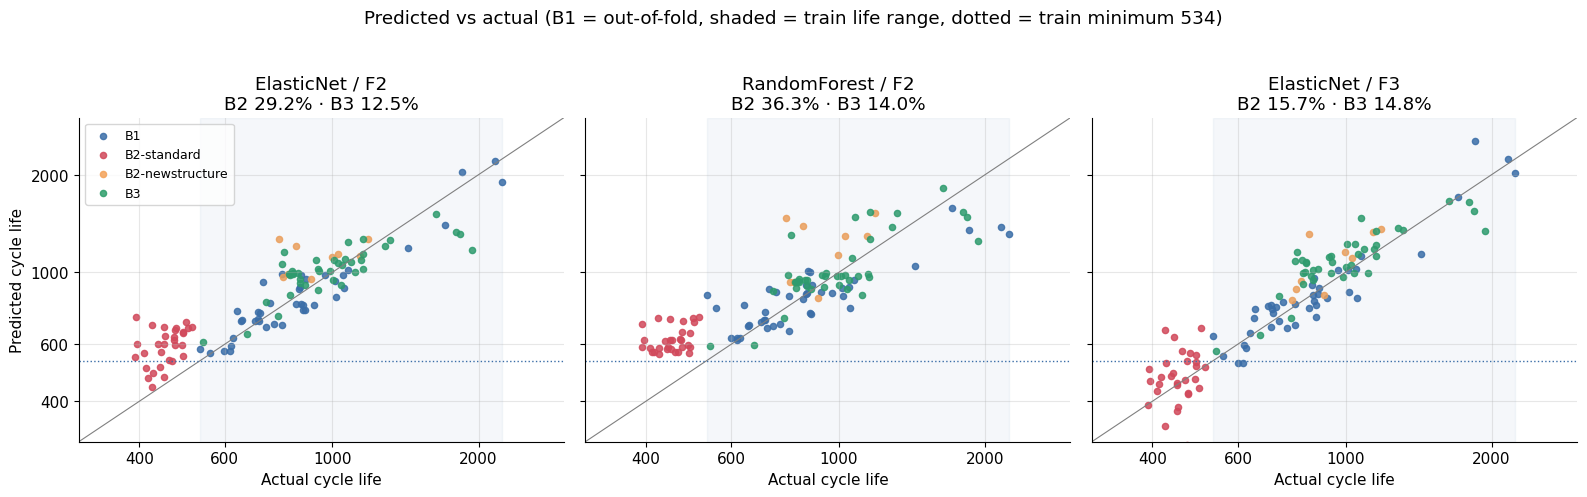

,min,median,max,actual_range
model,,,,
ElasticNet / F2,443,599,729,392 ~ 514
RandomForest / F2,560,606,728,392 ~ 514
ElasticNet / F3,294,471,672,392 ~ 514


In [6]:
models = ['ElasticNet / F2', 'RandomForest / F2', SEL]
tr_rng = data.loc[data.split == 'train', 'cycle_life'].agg(['min', 'max'])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True, sharey=True)
for ax, m in zip(axes, models):
    d = pred[pred.model == m]
    for g in GROUPS:
        dd = d[d.group == g]
        ax.scatter(dd.cycle_life, dd.pred_life, s=20, alpha=.85, color=GROUP_COLOR[g], label=g)
    ax.plot([300, 3000], [300, 3000], c='gray', lw=.8)
    ax.axvspan(*tr_rng, color='#3B6EA8', alpha=.05)
    ax.axhline(tr_rng['min'], ls=':', c='#3B6EA8', lw=1)
    r = perf.set_index('model').loc[m]
    ax.set(xscale='log', yscale='log', xlim=(300, 3000), ylim=(300, 3000), xlabel='Actual cycle life',
           title=f'{m}\nB2 {r.test_b2_mape:.1f}% · B3 {r.test_b3_mape:.1f}%')
    ticks = [400, 600, 1000, 2000]
    ax.set_xticks(ticks, [str(t) for t in ticks]); ax.set_yticks(ticks, [str(t) for t in ticks])
    ax.minorticks_off()
axes[0].set_ylabel('Predicted cycle life'); axes[0].legend(fontsize=9, loc='upper left')
plt.suptitle('Predicted vs actual (B1 = out-of-fold, shaded = train life range, dotted = train minimum 534)', y=1.03)
plt.tight_layout(); fig.savefig(FIG / 'pred_vs_actual.png', dpi=150, bbox_inches='tight'); plt.show()

b2s = pred[pred.group == 'B2-standard'].groupby('model').pred_life.agg(['min', 'median', 'max']).loc[models]
display(b2s.assign(actual_range='392 ~ 514').style.format(precision=0).set_caption('B2-standard 예측 수명 범위 (실제 392~514)'))

**[해석]**
- **RandomForest 는 B2-standard 를 560 사이클 아래로 예측하지 못합니다** (실제 392~514). 트리는 학습 데이터의 수명 범위 안에서만 값을 내므로, 학습 최솟값(534) 근처에서 예측이 막힙니다 → Day 1 의 외삽 한계 예상이 그대로 확인됩니다.
- 선형 모델은 학습 범위 아래로 예측할 수 있지만(F2 최소 443), logvar 만으로는 이동 폭이 부족해 **B2-standard 를 평균 +32% 과대예측**합니다(F3 는 +7%).
- F3 는 B2-standard 예측을 더 낮은 쪽으로 이동시켜 과대예측을 크게 줄입니다(4.3절).

### 4.2 피처셋 비교 — 배치 과적합 가설

**ISSUE** : Day 1 가설 "배치 간 부호가 바뀌는 피처(F3)·정책 피처(F3+Policy)는 Batch 1 에서는 좋아지고 새 배치에서는 나빠진다"가 맞는가?

,B1 OOF,B2 standard,B2 newstructure,Test B2,Test B3
feature_set,,,,,
F1,9.3,31.8,20.8,29.2,12.5
F2,9.3,31.8,20.8,29.2,12.5
F3,9.0,15.4,16.7,15.7,14.8
F3+Policy,10.0,28.8,12.4,25.0,12.5


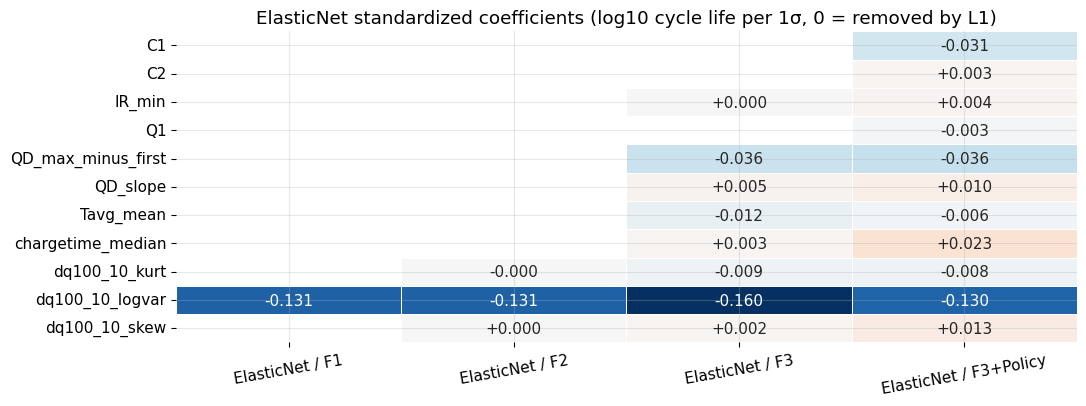

In [7]:
fs = perf[perf.algorithm.eq('ElasticNet')].set_index('feature_set').loc[['F1', 'F2', 'F3', 'F3+Policy']]
display(fs[['b1_oof_mape', 'test_b2_standard_mape', 'test_b2_newstructure_mape', 'test_b2_mape', 'test_b3_mape']]
        .rename(columns={'b1_oof_mape': 'B1 OOF', 'test_b2_standard_mape': 'B2 standard', 'test_b2_newstructure_mape': 'B2 newstructure',
                         'test_b2_mape': 'Test B2', 'test_b3_mape': 'Test B3'})
        .style.format(precision=1).set_caption('ElasticNet 피처셋 비교 (MAPE %)'))

en = [f'ElasticNet / {k}' for k in ['F1', 'F2', 'F3', 'F3+Policy']]
c = coef[en].loc[lambda d: d.abs().sum(axis=1) > 0]
fig, ax = plt.subplots(figsize=(11, 4.2))
sns.heatmap(c, annot=True, fmt='+.3f', cmap='RdBu_r', center=0, ax=ax, cbar=False, linewidths=.5)
ax.set_title('ElasticNet standardized coefficients (log10 cycle life per 1σ, 0 = removed by L1)'); ax.tick_params(axis='x', rotation=10)
plt.tight_layout(); plt.show()

**[해석]**
- **F2 = F1** : L1 정규화가 skew·kurt 계수를 0 으로 만들어 logvar 만 남았습니다. Batch 1 에서 skew·kurt 가 logvar 에 더하는 정보가 없다는 뜻입니다.
- **F3 (부호 불일치 피처 포함)** : Batch 2 는 29.2% → **15.7%** 로 크게 좋아졌지만, Batch 3 는 12.5% → 14.8% 로 나빠졌습니다 → 가설은 **Batch 3 에서는 맞고, Batch 2 에서는 틀렸습니다.** F3 의 추가 피처가 "어느 배치에나 통하는 신호"가 아니라 **배치마다 효과가 달라지는 신호**라는 Day 1 판단 자체는 확인됩니다.
- **F3+Policy** : 정책 피처를 더하면 Batch 1 OOF 가 9.0% → 10.0% 로 오히려 나빠지고, Batch 2 standard 도 15.4% → 28.8% 로 다시 나빠집니다 → **정책 설정값은 일반화에 도움이 되지 않는다**는 Day 1 판단이 맞았습니다.

### 4.3 F3 가 Batch 2 를 개선한 이유

**ISSUE** : F3 의 어떤 피처가 B2 예측을 바꿨으며, 그 신호는 물리적으로 타당한가?

In [8]:
b1 = data[data.batch == 1]
feats = FEATURE_SETS['F3']
w = coef[SEL].reindex(feats).fillna(0)
mu, sd = b1[feats].mean(), b1[feats].std(ddof=0)
contrib = data.groupby('group')[feats].median().sub(mu).div(sd).mul(w).reindex(GROUPS)
contrib['합계 (log10)'] = contrib.sum(axis=1)
contrib['수명 배율'] = 10 ** contrib['합계 (log10)']
display(contrib.style.format(precision=3).format({'수명 배율': '×{:.2f}'})
        .background_gradient(cmap='RdBu', vmin=-.1, vmax=.1, subset=feats)
        .set_caption(f'{SEL} : 그룹 중앙값 피처가 예측(log10 수명)을 B1 평균 대비 얼마나 이동시키는가'))

z = data.groupby('group').QD_max_minus_first.median().reindex(GROUPS)
print('초기 용량 상승폭 QD_max_minus_first 중앙값 (Ah) :', z.round(4).to_dict(),
      f'| B1 평균 {mu.QD_max_minus_first:.4f}, 표준편차 {sd.QD_max_minus_first:.4f}')

,dq100_10_logvar,dq100_10_skew,dq100_10_kurt,chargetime_median,QD_slope,QD_max_minus_first,IR_min,Tavg_mean,합계 (log10),수명 배율
group,,,,,,,,,,
B1,-0.034059,0.000097,0.000932,-0.000139,0.000327,0.014128,0.000000,-0.002057,-0.020770,×0.95
B2-standard,-0.193181,0.002862,0.000355,-0.001993,0.006026,-0.068403,0.000000,-0.004373,-0.258707,×0.55
B2-newstructure,0.141911,-0.000473,-0.029272,-0.002328,-0.007297,0.044020,-0.000000,-0.015295,0.131266,×1.35
B3,0.087563,-0.000140,-0.008875,-0.002321,-0.000010,0.045379,-0.000000,-0.019857,0.101738,×1.26


초기 용량 상승폭 QD_max_minus_first 중앙값 (Ah) : {'B1': 0.0045, 'B2-standard': 0.0082, 'B2-newstructure': 0.0032, 'B3': 0.0032} | B1 평균 0.0052, 표준편차 0.0016


**[해석]**
- B2-standard 예측을 가장 크게 낮춘 것은 logvar(−0.19, 수명 ×0.64)이고, 그다음이 **초기 용량 상승폭 `QD_max_minus_first` (−0.07, 수명 ×0.85)** 입니다. 둘을 합친 이동은 수명 ×0.55 입니다.
- B2-standard 셀은 초기 100 사이클 동안 용량이 중앙값 0.0082Ah 상승해(B1 평균 0.0052Ah 대비 +1.9σ), Day 1 Q2 에서 본 "초기 용량 상승 후 급락" 패턴을 피처로 포착합니다.
- 이 피처는 단독으로는 배치마다 상관 부호가 바뀌지만(B1 +0.56 / B2 −0.31), **logvar 를 함께 고려한 조건부 효과**에서는 "같은 ΔQ 분산이라면 초기 용량이 더 많이 오른 셀이 더 짧다"는 방향으로 B1 에서 학습되었고, 이것이 B2-standard 에 그대로 통했습니다.
- **도메인 해석** : 초기 용량 상승은 전극 활성화(웨팅)·온도 차이 등 시험 조건의 영향을 받는 값이라, Batch 3 처럼 조건이 다른 배치에서는 같은 방향으로 작동하지 않을 수 있습니다(B3 14.8%).

## 5. 오류 분석

**ISSUE** : 선택 모델이 가장 크게 틀린 셀은 어떤 공통점이 있고, 원인은 무엇이며, 어떻게 개선할 수 있는가?

,MAPE,평균_부호오차,과대예측_비율,n
group,,,,
B1,9.0,-0.1,46.3,41
B2-standard,15.4,6.7,60.0,30
B2-newstructure,16.7,15.5,88.9,9
B3,14.8,10.4,77.5,40


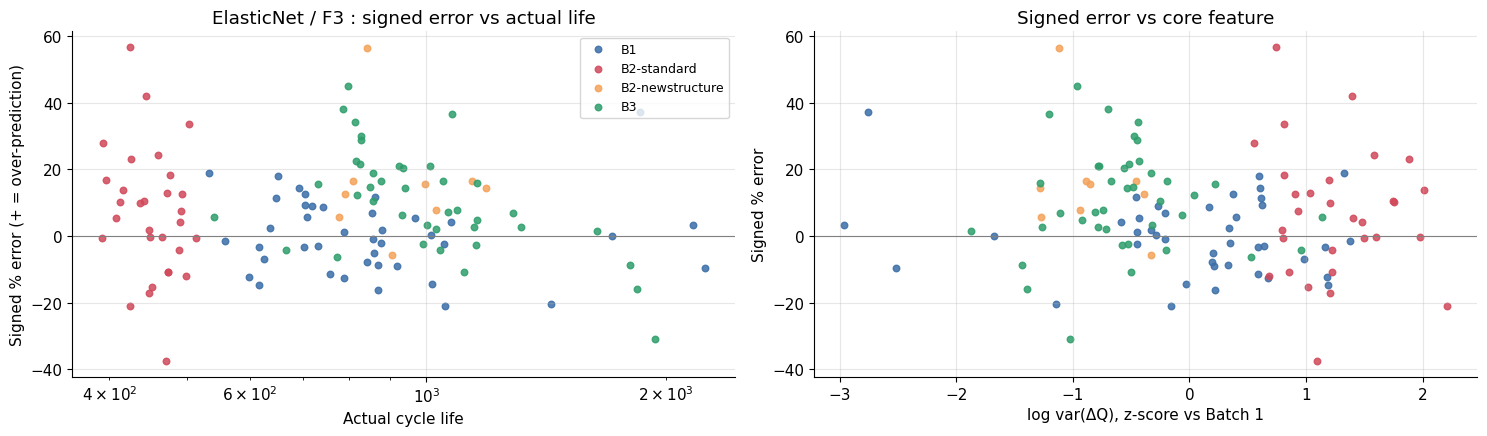

,cell_key,group,policy_base,cycle_life,pred_life,signed_pe,z_logvar,z_QD_rise
43,b2c2,B2-standard,5.2C(50%)-4.25C,424,664,+56.7,+0.74,+0.01
77,b2c44,B2-newstructure,5.2C(58%)-4C,841,1314,+56.2,-1.11,-1.51
116,b3c40,B3,5.6C(19%)-4.6C,796,1153,+44.9,-0.96,-0.40
45,b2c4,B2-standard,4.65C(69%)-6C,444,630,+42.0,+1.39,-2.66
117,b3c41,B3,5.6C(36%)-4.3C,786,1085,+38.1,-0.69,-0.49
58,b2c17,B2-standard,5.6C(26%)-4.5C,471,294,-37.6,+1.10,+8.15
89,b3c10,B3,4.8C(80%)-4.8C,1078,1471,+36.5,-1.20,-1.20
99,b3c20,B3,5C(67%)-4C,813,1090,+34.1,-0.44,-1.30
79,b2c46,B2-standard,4.8C(80%)-4.8C,503,672,+33.6,+0.81,+0.62
114,b3c38,B3,5C(67%)-4C,1935,1337,-30.9,-1.03,-1.65


Batch 3 : 부호오차와 실제 수명의 상관 r = -0.60


In [9]:
p = pred[pred.model == SEL].merge(data[['cell_key'] + FEATURE_SETS['F3']], on='cell_key')
bias = p.groupby('group').agg(MAPE=('ape', 'mean'), 평균_부호오차=('signed_pe', 'mean'),
                              과대예측_비율=('signed_pe', lambda x: (x > 0).mean() * 100), n=('ape', 'size')).reindex(GROUPS)
display(bias.style.format(precision=1).set_caption('그룹별 오차 (부호오차 + = 과대예측)'))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for g in GROUPS:
    d = p[p.group == g]
    axes[0].scatter(d.cycle_life, d.signed_pe, s=22, color=GROUP_COLOR[g], alpha=.85, label=g)
axes[0].axhline(0, c='gray', lw=.8)
axes[0].set(xscale='log', xlabel='Actual cycle life', ylabel='Signed % error (+ = over-prediction)', title=f'{SEL} : signed error vs actual life')
axes[0].legend(fontsize=9)
lv = p.assign(z_logvar=(p.dq100_10_logvar - mu.dq100_10_logvar) / sd.dq100_10_logvar)
for g in GROUPS:
    d = lv[lv.group == g]
    axes[1].scatter(d.z_logvar, d.signed_pe, s=22, color=GROUP_COLOR[g], alpha=.85)
axes[1].axhline(0, c='gray', lw=.8)
axes[1].set(xlabel='log var(ΔQ), z-score vs Batch 1', ylabel='Signed % error', title='Signed error vs core feature')
plt.tight_layout(); fig.savefig(FIG / 'error_analysis.png', dpi=150, bbox_inches='tight'); plt.show()

top = p[p.split.str.startswith('test')].nlargest(10, 'ape')
top = top.assign(z_logvar=(top.dq100_10_logvar - mu.dq100_10_logvar) / sd.dq100_10_logvar,
                 z_QD_rise=(top.QD_max_minus_first - mu.QD_max_minus_first) / sd.QD_max_minus_first)
display(top[['cell_key', 'group', 'policy_base', 'cycle_life', 'pred_life', 'signed_pe', 'z_logvar', 'z_QD_rise']]
        .style.format({'cycle_life': '{:.0f}', 'pred_life': '{:.0f}', 'signed_pe': '{:+.1f}', 'z_logvar': '{:+.2f}', 'z_QD_rise': '{:+.2f}'})
        .set_caption('테스트 오차 상위 10셀 (z = Batch 1 기준 표준화)'))
r3 = p[p.split == 'test_b3']
print(f'Batch 3 : 부호오차와 실제 수명의 상관 r = {r3.signed_pe.corr(r3.cycle_life):.2f}')

**[공통점]**
1. **대부분 과대예측입니다.** 테스트 상위 10셀 중 8셀이 과대예측이며, Batch 2 는 평균 +8.7%, Batch 3 는 평균 +10.4% 로 **새 배치에서 수명을 체계적으로 낙관**합니다(Batch 1 OOF 의 평균 부호오차는 거의 0).
2. **ΔQ 는 "보통"인데 실제로는 짧은 셀**입니다. 과대예측 상위 셀(b2c2, b2c4, b2c46 등)은 logvar z 가 B1 분포의 상단 부근(+0.7 ~ +1.4σ)이어서 모델은 630~672 사이클로 예측하지만, 실제 수명은 424~503 입니다.
3. **Batch 3 는 예측이 평균 쪽으로 압축**됩니다. 부호오차와 실제 수명의 상관이 −0.6 으로, 짧은 셀은 과대예측하고 긴 셀(b3c38, 1,935)은 과소예측합니다.
4. 반대로 **과소예측 1위(b2c17)는 초기 용량 상승폭이 +8σ 로 극단적**인 셀입니다. F3 의 개선 요인이 극단값에서는 지나치게 외삽되었습니다.

**[원인 가설]**
- **배치 수준 오프셋** : 같은 ΔQ 값이라도 배치(시험 구조·휴지 시간·충전 프로파일)에 따라 수명 수준이 다르며(Day 1 Q4 : 같은 정책도 배치 간 2~3배 차이), 이 차이는 초기 100 사이클의 ΔQ 에 충분히 드러나지 않습니다.
- **단일 배치 학습** : 학습 데이터가 한 배치뿐이라, 모델이 "배치가 바뀌면 수명 수준이 이동한다"는 변동을 학습할 기회가 없습니다.
- **선형 외삽의 양면성** : 선형 모델은 학습 범위 밖으로 예측할 수 있지만, 피처가 극단값이면 예측도 과도하게 이동합니다(b2c17).

**[개선 방향]**
- **배치 보정(calibration)** : 새 배치에서 일부 셀을 EOL 까지 시험해 얻은 소수 레이블로 절편(배치 오프셋)만 다시 맞춥니다.
- **학습 배치 다양화** : 원논문처럼 두 개 이상의 배치를 섞어 학습하면 배치 간 변동을 학습할 수 있습니다(같은 Batch 3 기준 원논문 Gap 1~4%p).
- **시험 조건 피처** : 휴지 시간, CV 컷오프 전류 등 배치 조건을 메타 피처로 추가합니다.
- **극단값 처리** : 피처를 학습 범위 근처로 제한(clipping)하거나 예측 구간(불확실성)을 함께 제공해, 극단값 셀은 "신뢰도 낮음"으로 표시합니다.

## 6. 요약 — 결과와 시사점

| 항목 | 결과 | 시사점 |
|---|---|---|
| 선택 모델 | **ElasticNet / F3** (Batch 1 OOF 9.0%) | 선형 + 정규화가 소표본·외삽 조건에 적합 (Day 1 전략과 일치) |
| 단계별 성능 | Train CV 8.5% · Valid 8.9% · Test B2 15.7% | Gap(Train−Valid) +0.4%p 로 과적합 없음, 성능 저하는 배치 이동(Gap Valid−Test +6.8%p)에서 발생 |
| 원논문 대비 | Gap(Target−Test) +6.6%p · 같은 데이터(B3 = secondary)에서는 +1.4~+4.1%p | 차이의 상당 부분은 테스트 배치의 분포 이동과 단일 배치 학습 때문 |
| Day 1 가설 | 외삽 한계(트리) 확인 · logvar 충분(F2 = F1) · 정책 피처 무익 · F3 는 B2 개선 / B3 악화 | 배치 간 일반화가 핵심 과제이며, 배치마다 효과가 다른 피처는 신중히 사용해야 함 |
| 오류 | 새 배치에서 체계적 과대예측(B2 +8.7%, B3 +10.4%) | 배치 보정·학습 배치 다양화가 가장 효과적인 개선 방향 |